# Day 5 · Intro to PyTorch & Tensors
The Day 2 regression, ported to PyTorch: `torch.tensor`, `.to('cuda')`, `loss.backward()`.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
df = pd.read_csv("crop_yield.csv")          # put crop_yield.csv next to this notebook
print(df.shape)
df.head()

(1000000, 10)


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
0,West,Sandy,Cotton,897.077239,27.676966,False,True,Cloudy,122,6.555816
1,South,Clay,Rice,992.673282,18.026142,True,True,Rainy,140,8.527341
2,North,Loam,Barley,147.998025,29.794042,False,False,Sunny,106,1.127443
3,North,Sandy,Soybean,986.866331,16.644190,False,True,Rainy,146,6.517573
4,South,Silt,Wheat,730.379174,31.620687,True,True,Cloudy,110,7.248251


In [2]:
NUM = ["Rainfall_mm", "Temperature_Celsius", "Fertilizer_Used", "Irrigation_Used", "Days_to_Harvest"]
X_all = df[NUM].astype(float).to_numpy()
y_all = df["Yield_tons_per_hectare"].to_numpy()
rng = np.random.default_rng(42)
idx = rng.permutation(len(df)); cut = int(0.8 * len(df))
tr, te = idx[:cut], idx[cut:]
mu, sd = X_all[tr].mean(0), X_all[tr].std(0)
Xtr = np.c_[np.ones(len(tr)), (X_all[tr]-mu)/sd]; ytr = y_all[tr]
Xte = np.c_[np.ones(len(te)), (X_all[te]-mu)/sd]; yte = y_all[te]

In [3]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")   # falls back to CPU if no GPU
print("device:", device)

Xt  = torch.tensor(Xtr, dtype=torch.float32).to(device); yt  = torch.tensor(ytr, dtype=torch.float32).to(device)
Xtt = torch.tensor(Xte, dtype=torch.float32).to(device); ytt = torch.tensor(yte, dtype=torch.float32).to(device)

w = torch.zeros(Xt.shape[1], device=device, requires_grad=True)   # bias is column 0, as in Day 2
lr, epochs = 0.02, 300
losses = []
for epoch in range(epochs):
    loss = ((Xt @ w - yt) ** 2).mean()
    loss.backward()                       # autograd computes dLoss/dw
    with torch.no_grad():
        w -= lr * w.grad
    w.grad.zero_()
    losses.append(loss.item())
    if epoch % 50 == 0 or epoch == epochs - 1:
        print(f"epoch {epoch:3d}  loss {loss.item():.4f}")

device: cpu
epoch   0  loss 24.4956


epoch  50  loss 0.6598


epoch 100  loss 0.2576


epoch 150  loss 0.2508


epoch 200  loss 0.2507


epoch 250  loss 0.2507


epoch 299  loss 0.2507


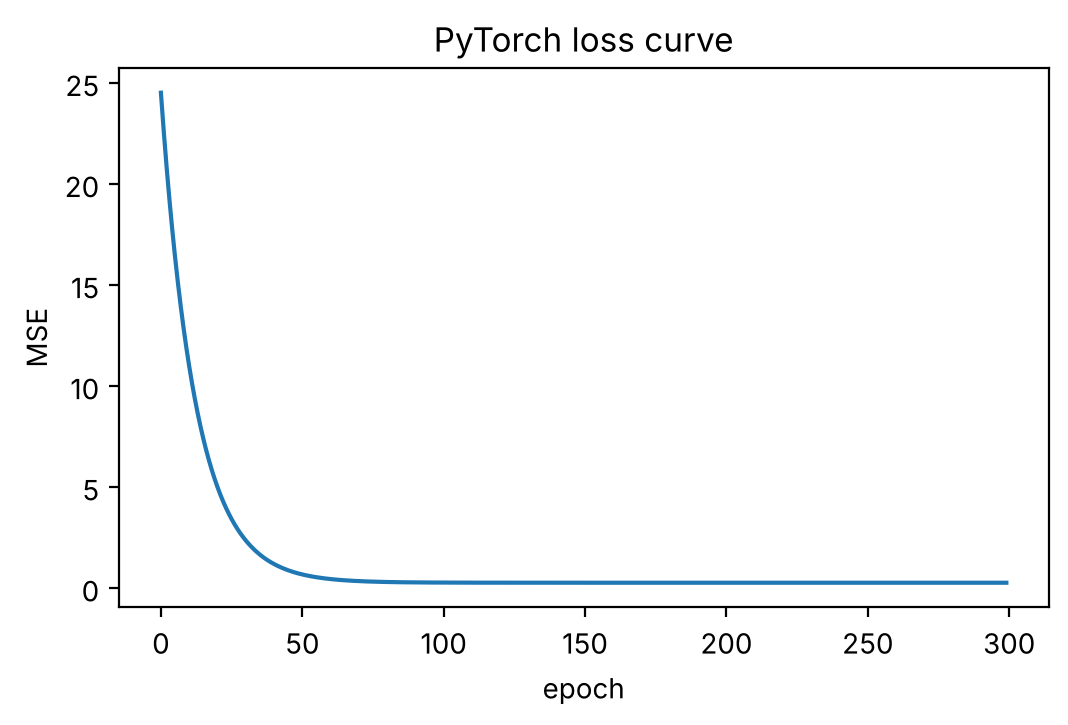

torch weights : [4.6495e+00 1.2980e+00 1.4400e-01 7.4990e-01 5.9960e-01 7.0000e-04]
Day 2 weights : [4.6495e+00 1.2980e+00 1.4400e-01 7.4990e-01 5.9960e-01 7.0000e-04]
test MSE: 0.24959507584571838


In [4]:
plt.figure(figsize=(6, 3.5)); plt.plot(losses); plt.xlabel("epoch"); plt.ylabel("MSE"); plt.title("PyTorch loss curve"); plt.show()

w_np = np.load("day2_weights.npy") if __import__("os").path.exists("day2_weights.npy") else np.linalg.lstsq(Xtr, ytr, rcond=None)[0]
print("torch weights :", np.round(w.detach().cpu().numpy(), 4))
print("Day 2 weights :", np.round(w_np, 4))
print("test MSE:", ((Xtt @ w - ytt) ** 2).mean().item())